# Used-car asking price prediction
**Mpumelelo Nhlapo · Data Science Capstone Project**

Can vehicle listing details predict a used car's asking price? This project compares a median baseline, Gradient Boosting and Random Forest on the same fixed split, then examines where the Random Forest makes its largest errors.



In [1]:
from pathlib import Path
import hashlib
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.ticker import FuncFormatter
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

DATA_PATH = Path("data/used_cars_dataset.csv")
SEED = 42
REFERENCE_YEAR = 2024
TARGET = "AskPrice"
NUMERIC = ["Year", "kmDriven"]
CATEGORICAL = ["Brand", "model", "Transmission", "FuelType"]
FEATURES = NUMERIC + CATEGORICAL

if not DATA_PATH.is_file():
    raise FileNotFoundError(f"Place the original CSV at {DATA_PATH}. See README.md.")

raw = pd.read_csv(DATA_PATH)
required = {*FEATURES, TARGET, "Age", "AdditionInfo"}
missing = required.difference(raw.columns)
if missing:
    raise ValueError(f"Missing CSV columns: {', '.join(sorted(missing))}")

print(f"CSV SHA-256: {hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()}")
print(f"Raw rows: {len(raw):,}")

CSV SHA-256: 415856e7fe34421da56b6e5363d43305f19cd63c27040f98e4b8b55d9bac5f80
Raw rows: 24,575


## 1. Clean the listings

Remove exact duplicates and retain finite, positive asking prices. Standardise text and parse prices and mileage. Recover some missing details from each listing's own description. The rules can misread seller text, so the notebook reports how often they fill missing fields.

In [2]:
df = raw.drop_duplicates().copy()
unique_count = len(df)
df[TARGET] = pd.to_numeric(
    df[TARGET].astype("string").str.replace(r"[₹,\s]", "", regex=True),
    errors="coerce",
).astype(float)
df = df.loc[np.isfinite(df[TARGET]) & df[TARGET].gt(0)].copy()

placeholders = ["", "unknown", "nan", "n/a", "na", "null", "none"]
for column in CATEGORICAL:
    values = (
        df[column].astype("string").str.lower()
        .str.replace(r"[-,]", " ", regex=True)
        .str.replace(r"\s+", " ", regex=True).str.strip()
    )
    df[column] = values.replace(placeholders, pd.NA)

df["Brand"] = df["Brand"].replace({"maruti": "maruti suzuki", "mercedes": "mercedes benz"})
year = pd.to_numeric(df["Year"], errors="coerce")
df["Year"] = year.where(year.between(1990, REFERENCE_YEAR))
age = pd.to_numeric(df["Age"], errors="coerce")
mileage = pd.to_numeric(
    df["kmDriven"].astype("string").str.replace(r"(?i),|\s*km[s]?\s*$", "", regex=True),
    errors="coerce",
)
df["kmDriven"] = mileage.where(np.isfinite(mileage) & mileage.ge(0)).astype(float)
missing_before = df[FEATURES].isna().sum()
descriptions = df["AdditionInfo"].fillna("").astype(str).str.lower()
normalised_descriptions = descriptions.str.replace(r"[^a-z0-9\s]", " ", regex=True)

print(f"Exact duplicates removed: {len(raw) - unique_count:,}")
print(f"Invalid targets removed: {unique_count - len(df):,}")
print(f"Listings used: {len(df):,}")

Exact duplicates removed: 9,587
Invalid targets removed: 0
Listings used: 14,988


In [3]:
brands = (
    "maruti suzuki", "maruti", "toyota", "honda", "volkswagen", "bmw", "ford",
    "hyundai", "kia", "mercedes benz", "mercedes", "audi", "renault", "mg",
    "skoda", "tata", "mahindra", "jeep", "mini", "volvo", "land rover", "jaguar",
)
brand_pattern = r"\b(" + "|".join(map(re.escape, brands)) + r")\b"
brand_matches = normalised_descriptions.str.extract(brand_pattern, expand=False)
df["Brand"] = df["Brand"].fillna(
    brand_matches.replace({"maruti": "maruti suzuki", "mercedes": "mercedes benz"})
)

model_rules = [('\\bbr[\\s-]?v\\b', 'br-v'), ('\\brange\\s+rover\\s+evoque\\b|\\brange\\s+evoque\\b', 'range rover evoque'), ('\\bvanquish\\b', 'vanquish'), ('\\bgurkha\\b', 'gurkha'), ('\\balto\\s*k10\\b', 'alto k10'), ('\\bpajero\\s+sport\\b', 'pajero sport'), ('\\bc(?:i|e)dia\\b', 'cedia'), ('\\bd[\\s-]?max\\b', 'd-max'), ('\\bvitara\\s+brezza\\b|\\bbrezza\\b', 'vitara brezza'), ('\\bmaruti\\s+suzuki\\s+zen\\b|\\bzen\\s+vxi\\b', 'zen'), ('\\blx\\s*500d\\b', 'lx 500d'), ('\\bchevrolet\\s+beat\\b', 'beat'), ('\\bxuv\\s*500\\b', 'xuv500')]
for pattern, label in model_rules:
    matches = df["model"].isna() & descriptions.str.contains(pattern, regex=True)
    df.loc[matches, "model"] = label.replace("-", " ")

text_rules = {
    "Transmission": [
        (r"\b(?:automatic|cvt|amt|dct|dsg)\b", "automatic"),
        (r"\bmanual\b", "manual"),
    ],
    "FuelType": [
        (r"\b(?:diesel|crdi|tdi)\b", "diesel"),
        (r"\b(?:petrol|vtec|tsi)\b", "petrol"),
        (r"\bcng\b", "cng"),
        (r"\blpg\b", "lpg"),
    ],
}
for column, rules in text_rules.items():
    for pattern, label in rules:
        matches = df[column].isna() & descriptions.str.contains(pattern, regex=True)
        df.loc[matches, column] = label

year_from_age = REFERENCE_YEAR - age
year_from_text = pd.to_numeric(
    descriptions.str.extract(r"\b((?:19|20)\d{2})\b", expand=False), errors="coerce"
)
df["Year"] = (
    df["Year"].fillna(year_from_age.where(year_from_age.between(1990, REFERENCE_YEAR)))
    .fillna(year_from_text.where(year_from_text.between(1990, REFERENCE_YEAR)))
)
mileage_from_text = pd.to_numeric(
    descriptions.str.extract(
        r"(?<![\d.,])([\d,]+)\s*(?:kms?|kilometers|kilometres)\b", expand=False
    ).str.replace(",", "", regex=False),
    errors="coerce",
)
df["kmDriven"] = df["kmDriven"].fillna(
    mileage_from_text.where(mileage_from_text.between(0, 1_000_000))
)
for column in CATEGORICAL:
    df[column] = df[column].astype(object).where(df[column].notna(), np.nan)

display(pd.DataFrame({
    "Missing before recovery": missing_before,
    "Still missing": df[FEATURES].isna().sum(),
}))

,Missing before recovery,Still missing
Year,5164,83
kmDriven,3148,2857
Brand,5215,378
model,5233,4996
Transmission,2970,2645
FuelType,5237,507


## 2. Split the data and explore the training set

An 80/20 split with seed 42 gives every model the same test listings. The input features are year, mileage, brand, model, transmission and fuel type. Age and description text help recover missing fields upstream. The description itself stays out of the model.

Training: 11,990 | Test: 2,998


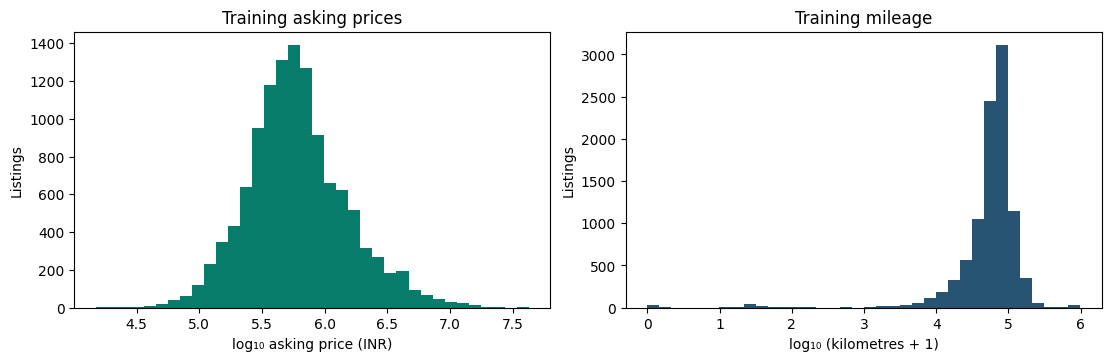

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    df[FEATURES], df[TARGET], test_size=0.20, random_state=SEED,
)
assert X_train.index.intersection(X_test.index).empty
print(f"Training: {len(X_train):,} | Test: {len(X_test):,}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), layout="constrained")
axes[0].hist(np.log10(y_train), bins=36, color="#087C6B")
axes[0].set(title="Training asking prices", xlabel="log₁₀ asking price (INR)", ylabel="Listings")
axes[1].hist(np.log10(X_train["kmDriven"].dropna() + 1), bins=36, color="#275473")
axes[1].set(title="Training mileage", xlabel="log₁₀ (kilometres + 1)", ylabel="Listings")
plt.show()

## 3. Train and evaluate the models

Fit numerical medians, the categorical missing-value treatment and one-hot encoding inside each training pipeline. The median baseline gives a reference point for interpreting MAE. All metrics use the original asking-price scale. MAE measures the average absolute error, RMSE gives larger errors more weight, and R² measures the share of test-set variance explained.

In [5]:
def make_pipeline(regressor):
    preprocess = ColumnTransformer([
        ("numeric", SimpleImputer(strategy="median"), NUMERIC),
        ("categorical", Pipeline([
            ("fill", SimpleImputer(strategy="constant", fill_value="unknown")),
            ("encode", OneHotEncoder(handle_unknown="ignore")),
        ]), CATEGORICAL),
    ])
    return Pipeline([("preprocess", preprocess), ("regressor", regressor)])


models = {
    "Median baseline": DummyRegressor(strategy="median"),
    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=200, learning_rate=0.05, max_depth=3,
        min_samples_split=5, min_samples_leaf=3, random_state=SEED,
    ),
    "Random Forest": RandomForestRegressor(
        n_estimators=100, random_state=SEED, n_jobs=2,
    ),
}
predictions = {}
rows = []
for name, regressor in models.items():
    pipeline = make_pipeline(regressor)
    pipeline.fit(X_train, y_train)
    predicted = pipeline.predict(X_test)
    assert np.isfinite(predicted).all()
    predictions[name] = predicted
    rows.append({
        "Model": name,
        "MAE (INR)": mean_absolute_error(y_test, predicted),
        "RMSE (INR)": np.sqrt(mean_squared_error(y_test, predicted)),
        "R²": r2_score(y_test, predicted),
    })

results = pd.DataFrame(rows).set_index("Model").sort_values("MAE (INR)")
display(results.style.format({"MAE (INR)": "{:,.0f}", "RMSE (INR)": "{:,.0f}", "R²": "{:.3f}"}))

,MAE (INR),RMSE (INR),R²
Model,,,
Random Forest,"259,623","910,384",0.714
Gradient Boosting,"368,866","1,113,206",0.573
Median baseline,"678,667","1,763,281",-0.072


## 4. Inspect Random Forest errors by price band

The main model is the Random Forest. The counts show how many test listings support each estimate. Median absolute percentage error helps compare relative error across differently priced cars.

,Listings,MAE_INR,Median_APE_pct
Price band,,,
≤500k,1281,"85,879",20.0%
500k–1m,933,"147,620",12.6%
1m–3m,625,"351,884",13.6%
>3m,159,"1,953,983",20.9%


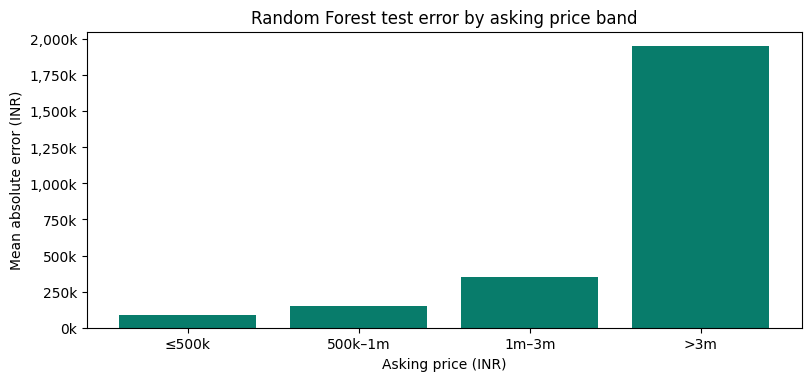

In [6]:
review = pd.DataFrame({"Actual": y_test, "Predicted": predictions["Random Forest"]})
review["Absolute error"] = (review["Actual"] - review["Predicted"]).abs()
review["Absolute percentage error"] = 100 * review["Absolute error"] / review["Actual"]
review["Price band"] = pd.cut(
    review["Actual"], [0, 500_000, 1_000_000, 3_000_000, np.inf],
    labels=["≤500k", "500k–1m", "1m–3m", ">3m"],
)
band_summary = review.groupby("Price band", observed=True).agg(
    Listings=("Actual", "size"),
    MAE_INR=("Absolute error", "mean"),
    Median_APE_pct=("Absolute percentage error", "median"),
)
display(band_summary.style.format({"MAE_INR": "{:,.0f}", "Median_APE_pct": "{:.1f}%"}))

fig, ax = plt.subplots(figsize=(8, 3.7), layout="constrained")
ax.bar(band_summary.index.astype(str), band_summary["MAE_INR"], color="#087C6B")
ax.yaxis.set_major_formatter(FuncFormatter(lambda value, _: f"{value / 1_000:,.0f}k"))
ax.set(title="Random Forest test error by asking price band", xlabel="Asking price (INR)",
       ylabel="Mean absolute error (INR)")
plt.show()

## 5. Limitations

- The CSV contains advertised asking prices. Estimating transaction prices would require sale records.
- Exact duplicate removal does not identify every possible repeat listing. Future evaluation should check for repeated vehicles and use a later collection period.
- Seller descriptions can contain ambiguous years, mileage and vehicle names. The historical 2024 year assumption should be reviewed before applying these rules to new data.
- This run revisits the capstone dataset and split design. A fresh holdout would better measure generalisation, particularly for expensive or rare cars.
